# Fig. 5 Supplementary Figure 2 panels a-h

This notebook redraws SFig2 panels a-h. Each plotted panel is generated in its own cell, and the reproducible data bundle is stored under `data/sfig2`.


In [1]:
import omicverse as ov
import scanpy as sc
import matplotlib.pyplot as plt
ov.plot_set(font_path='Arial')
sc.settings.set_figure_params(dpi=300, vector_friendly=True)
plt.rcParams['pdf.fonttype'] = 42
plt.rcParams['ps.fonttype'] = 42
plt.rcParams.update({
    'font.size': 18,
    'axes.titlesize': 18,
    'axes.labelsize': 18,
    'xtick.labelsize': 18,
    'ytick.labelsize': 18,
    'legend.fontsize': 18,
    'axes.linewidth': 1.8,
    'xtick.major.width': 1.6,
    'ytick.major.width': 1.6,
})


/opt/miniforge/envs/omicverse_working/lib/python3.11/site-packages/scanpy/_utils/__init__.py:33: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('anndata')` instead.
  from anndata import __version__ as anndata_version
/opt/miniforge/envs/omicverse_working/lib/python3.11/site-packages/scanpy/__init__.py:24: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('anndata')` instead.
  if Version(anndata.__version__) >= Version("0.11.0rc2"):
/opt/miniforge/envs/omicverse_working/lib/python3.11/site-packages/scanpy/readwrite.py:16: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('anndata')` instead.
  if Version(anndata.__version__) >= Version("0.11.0rc2"):


/opt/miniforge/envs/omicverse_working/lib/python3.11/site-packages/louvain/__init__.py:54: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import get_distribution, DistributionNotFound


/opt/miniforge/envs/omicverse_working/lib/python3.11/site-packages/requests/__init__.py:113: RequestsDependencyWarning: urllib3 (2.6.3) or chardet (7.1.0)/charset_normalizer (3.4.3) doesn't match a supported version!
  warnings.warn(
/opt/miniforge/envs/omicverse_working/lib/python3.11/site-packages/anndata/__init__.py:70: FutureWarning: Importing read_loom from `anndata` is deprecated. Import anndata.io.read_loom instead.
  return module_get_attr_redirect(attr_name, deprecated_mapping=_DEPRECATED)


🔬 Starting plot initialization...
Using already downloaded Arial font from: /tmp/omicverse_arial.ttf


Registered as: Arial
🧬 Detecting GPU devices…
✅ NVIDIA CUDA GPUs detected: 8
    • [CUDA 0] NVIDIA GeForce RTX 4090 D
      Memory: 23.5 GB | Compute: 8.9
    • [CUDA 1] NVIDIA GeForce RTX 4090 D
      Memory: 23.5 GB | Compute: 8.9
    • [CUDA 2] NVIDIA GeForce RTX 4090 D
      Memory: 23.5 GB | Compute: 8.9
    • [CUDA 3] NVIDIA GeForce RTX 4090 D
      Memory: 23.5 GB | Compute: 8.9
    • [CUDA 4] NVIDIA GeForce RTX 4090 D
      Memory: 23.5 GB | Compute: 8.9
    • [CUDA 5] NVIDIA GeForce RTX 4090 D
      Memory: 23.5 GB | Compute: 8.9
    • [CUDA 6] NVIDIA GeForce RTX 4090 D
      Memory: 23.5 GB | Compute: 8.9
    • [CUDA 7] NVIDIA GeForce RTX 4090 D
      Memory: 23.5 GB | Compute: 8.9

   ____            _     _    __                  
  / __ \____ ___  (_)___| |  / /__  _____________ 
 / / / / __ `__ \/ / ___/ | / / _ \/ ___/ ___/ _ \ 
/ /_/ / / / / / / / /__ | |/ /  __/ /  (__  )  __/ 
\____/_/ /_/ /_/_/\___/ |___/\___/_/  /____/\___/                                           

In [2]:
from pathlib import Path
import hashlib
import json
import matplotlib as mpl
import fitz
import numpy as np
import pandas as pd
from IPython.display import Image as IPyImage, display
from matplotlib.lines import Line2D
from scipy.stats import pearsonr

try:
    from adjustText import adjust_text
except Exception:
    adjust_text = None

ROOT = Path('.').resolve()
DATA = ROOT / 'data' / 'sfig2'
OUT = ROOT / 'outputs'
PANEL_DIR = OUT / 'sfig2_panels'
TABLE_DIR = OUT / 'sfig2_tables'
INTERMEDIATE_DIR = OUT / 'sfig2_intermediate'
MANIFEST = ROOT / 'MANIFEST_sfig2.json'
for path in [PANEL_DIR, TABLE_DIR, INTERMEDIATE_DIR]:
    path.mkdir(parents=True, exist_ok=True)

def require_path(path):
    path = Path(path)
    if not path.exists():
        raise FileNotFoundError(path)
    return path

def display_pdf_page(pdf_path, zoom=1.4):
    doc = fitz.open(str(require_path(pdf_path)))
    pix = doc[0].get_pixmap(matrix=fitz.Matrix(zoom, zoom), alpha=False)
    display(IPyImage(data=pix.tobytes('png')))

def save_and_display(fig, stem, zoom=1.4, tight=True):
    pdf = PANEL_DIR / f'{stem}.pdf'
    png = PANEL_DIR / f'{stem}.png'
    kwargs = {'bbox_inches': 'tight', 'pad_inches': 0.03} if tight else {}
    fig.savefig(pdf, dpi=300, **kwargs)
    fig.savefig(png, dpi=300, **kwargs)
    plt.close(fig)
    print(f'saved: {pdf}')
    print(f'saved: {png}')
    display_pdf_page(pdf, zoom=zoom)

def style_axis(ax):
    ax.grid(False)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_linewidth(1.8)
    ax.spines['bottom'].set_linewidth(1.8)
    ax.tick_params(axis='both', which='both', width=1.6, length=5)

def style_heatmap_axis(ax):
    ax.grid(False)
    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_linewidth(1.8)
    ax.tick_params(axis='both', which='both', width=1.6, length=5)

def style_colorbar(cb):
    cb.ax.grid(False)
    cb.outline.set_linewidth(1.8)
    cb.ax.tick_params(axis='both', which='both', width=1.6, length=5)

def clean_image_axis(ax):
    ax.set_xticks([])
    ax.set_yticks([])
    ax.grid(False)
    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_linewidth(1.8)
        spine.set_edgecolor('black')

def row_zscore(frame):
    values = frame.astype(float)
    mean = values.mean(axis=1)
    std = values.std(axis=1).replace(0, np.nan)
    return values.sub(mean, axis=0).div(std, axis=0).fillna(0.0)

def natural_key(value):
    text = str(value).replace('D', '')
    try:
        return (0, int(float(text)))
    except ValueError:
        return (1, text)

def domain_display_label(value):
    return f'D{int(value)}'

def spatial_threshold_map(ax, cancer, threshold, thumb, page):
    selected = cancer['he_cancer_region_proxy_score'] >= threshold
    ax.imshow(thumb, extent=(0, page['width'], page['height'], 0), alpha=0.55)
    ax.scatter(cancer['center_x'], cancer['center_y'], s=1.5, c='#d0d0d0', alpha=0.32, linewidths=0, rasterized=True)
    ax.scatter(cancer.loc[selected, 'center_x'], cancer.loc[selected, 'center_y'], s=4.5, c='#d73027', alpha=0.88, linewidths=0, rasterized=True)
    ax.set_title(f'Threshold {threshold:.2f}')
    clean_image_axis(ax)

def sha256_file(path):
    h = hashlib.sha256()
    with Path(path).open('rb') as handle:
        for block in iter(lambda: handle.read(1024 * 1024), b''):
            h.update(block)
    return h.hexdigest()

def refresh_manifest():
    records = []
    for base in [DATA, ROOT / 'scripts' / 'sfig2', PANEL_DIR, TABLE_DIR, INTERMEDIATE_DIR]:
        if not base.exists():
            continue
        for path in sorted(base.rglob('*')):
            if path.is_file():
                records.append({'path': str(path.relative_to(ROOT)), 'size_bytes': path.stat().st_size, 'sha256': sha256_file(path)})
    payload = {
        'name': 'fig5_supplementary_2_reproduce',
        'root': str(ROOT),
        'notebook': str(ROOT / 'fig5_supplementary_2.ipynb'),
        'description': 'Minimal reproducible bundle for SFig2 panels a-h.',
        'sources': [
            'OmicOS_9/notebooks/supp_fig3_cancer_threshold_sensitivity.ipynb',
            'OmicOS_9/notebooks/supp_fig4_luad_region_quantification.ipynb',
            'OmicOS_7/non_he_analysis.ipynb',
            'Panel e additionally uses OmicOS_3/outputs/tables/visium_marker_validation_by_gigapath_domain_omicos3.csv because that table generates the D0-D11 marker heatmap shown in the supplied SFig2 image.',
        ],
        'panel_mapping': {
            'a': 'Selected tumor-enriched tile fraction',
            'b': 'Tumor and immune enrichment',
            'c': 'Threshold-set Jaccard similarity',
            'd': 'Threshold spatial maps',
            'e': 'Morphology-domain tile counts and marker heatmap',
            'f': 'Gene mean and variance correlation',
            'g': 'High/low-risk enriched region tile fractions',
            'h': 'Proxy differences of high/low-risk enriched regions',
        },
        'files': records,
    }
    MANIFEST.write_text(json.dumps(payload, indent=2), encoding='utf-8')
    return pd.DataFrame(records)


In [3]:
required = [
    DATA / 'threshold_sensitivity' / 'tables' / 'supp_fig3_threshold_sensitivity_summary.csv',
    DATA / 'threshold_sensitivity' / 'tables' / 'supp_fig3_threshold_jaccard.csv',
    DATA / 'threshold_sensitivity' / 'inputs' / 'he_cancer_proxy_and_tumor_immune_tiles.csv',
    DATA / 'threshold_sensitivity' / 'inputs' / 'visium_hd_he_thumbnail_stride32.npy',
    DATA / 'threshold_sensitivity' / 'inputs' / 'visium_hd_he_page_info.json',
    DATA / 'domain_marker_validation' / 'tables' / 'visium_marker_validation_by_gigapath_domain_omicos3.csv',
    DATA / 'domain_marker_validation' / 'inputs' / 'visium_hd_tile_features_minimal.csv',
    DATA / 'non_he_validation' / 'tables' / 'full_data_predicted_vs_visium_gene_calibration_omicos7.csv',
    DATA / 'luad_region_quantification' / 'tables' / 'supp_fig4_luad_region_composition.csv',
    DATA / 'luad_region_quantification' / 'tables' / 'supp_fig4_luad_region_proxy_tests.csv',
]
for path in required:
    require_path(path)
bundle_summary = pd.DataFrame({
    'component': ['threshold_sensitivity', 'domain_marker_validation', 'non_he_validation', 'luad_region_quantification'],
    'n_files': [
        sum(1 for p in (DATA / 'threshold_sensitivity').rglob('*') if p.is_file()),
        sum(1 for p in (DATA / 'domain_marker_validation').rglob('*') if p.is_file()),
        sum(1 for p in (DATA / 'non_he_validation').rglob('*') if p.is_file()),
        sum(1 for p in (DATA / 'luad_region_quantification').rglob('*') if p.is_file()),
    ],
})
display(bundle_summary)


                    component  n_files
0       threshold_sensitivity       13
1    domain_marker_validation        4
2           non_he_validation        7
3  luad_region_quantification       11

## Panel a


saved: ./outputs/sfig2_panels/sfig2_A_selected_tile_fraction.pdf
saved: ./outputs/sfig2_panels/sfig2_A_selected_tile_fraction.png


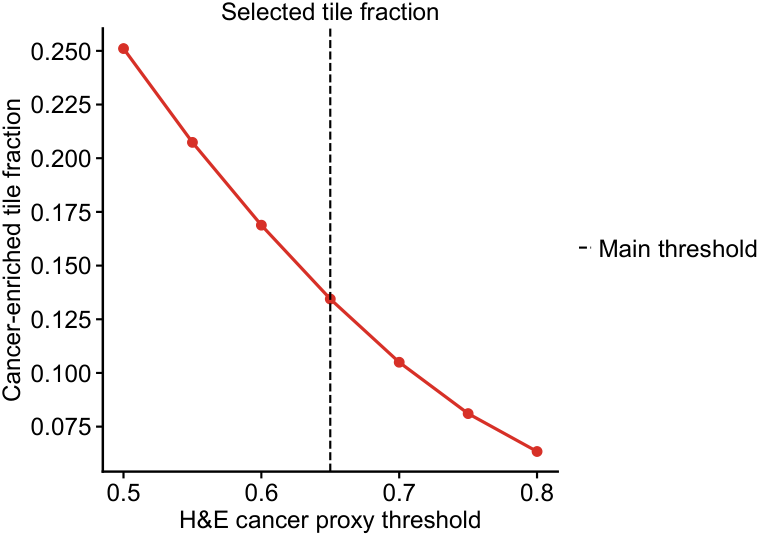

In [4]:
summary = pd.read_csv(DATA / 'threshold_sensitivity' / 'tables' / 'supp_fig3_threshold_sensitivity_summary.csv')
fig, ax = plt.subplots(figsize=(6, 6))
ax.plot(summary['threshold'], summary['cancer_tile_fraction'], marker='o', color='#d73027', linewidth=2.4, markersize=7)
ax.axvline(0.65, color='black', linestyle='--', linewidth=1.6, label='Main threshold')
ax.set_xlabel('H&E cancer proxy threshold')
ax.set_ylabel('Cancer-enriched tile fraction')
ax.set_title('Selected tile fraction')
style_axis(ax)
ax.legend(frameon=False, loc='center left', bbox_to_anchor=(1.02, 0.5), handletextpad=0.3)
save_and_display(fig, 'sfig2_A_selected_tile_fraction', zoom=1.35)


## Panel b


saved: ./outputs/sfig2_panels/sfig2_B_tumor_immune_enrichment.pdf
saved: ./outputs/sfig2_panels/sfig2_B_tumor_immune_enrichment.png


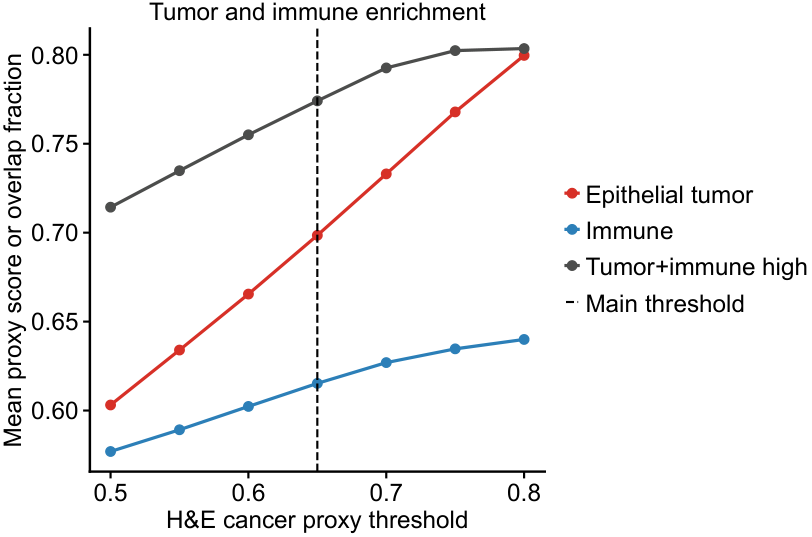

In [5]:
summary = pd.read_csv(DATA / 'threshold_sensitivity' / 'tables' / 'supp_fig3_threshold_sensitivity_summary.csv')
fig, ax = plt.subplots(figsize=(6, 6))
ax.plot(summary['threshold'], summary['mean_epithelial_tumor'], marker='o', label='Epithelial tumor', color='#d73027', linewidth=2.4, markersize=7)
ax.plot(summary['threshold'], summary['mean_immune'], marker='o', label='Immune', color='#2C7FB8', linewidth=2.4, markersize=7)
ax.plot(summary['threshold'], summary['tumor_immune_overlap_fraction'], marker='o', label='Tumor+immune high', color='#4d4d4d', linewidth=2.4, markersize=7)
ax.axvline(0.65, color='black', linestyle='--', linewidth=1.6, label='Main threshold')
ax.set_xlabel('H&E cancer proxy threshold')
ax.set_ylabel('Mean proxy score or overlap fraction')
ax.set_title('Tumor and immune enrichment')
style_axis(ax)
ax.legend(frameon=False, loc='center left', bbox_to_anchor=(1.02, 0.5), handletextpad=0.3)
save_and_display(fig, 'sfig2_B_tumor_immune_enrichment', zoom=1.35)


## Panel c


saved: ./outputs/sfig2_panels/sfig2_C_threshold_jaccard.pdf
saved: ./outputs/sfig2_panels/sfig2_C_threshold_jaccard.png


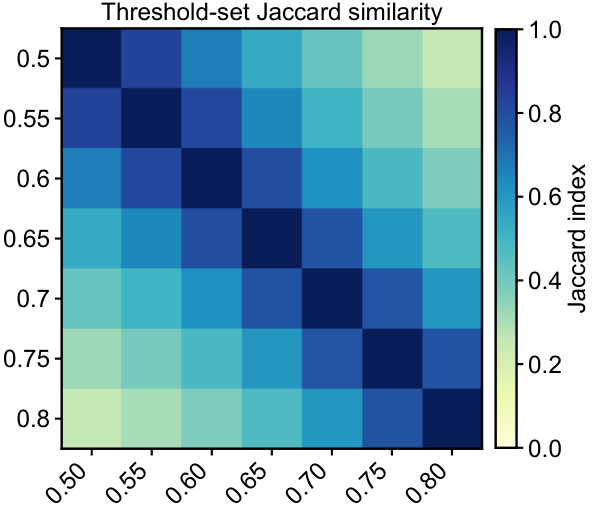

In [6]:
jaccard = pd.read_csv(DATA / 'threshold_sensitivity' / 'tables' / 'supp_fig3_threshold_jaccard.csv', index_col=0)
fig, ax = plt.subplots(figsize=(6, 6))
im = ax.imshow(jaccard.to_numpy(float), cmap='YlGnBu', vmin=0, vmax=1)
ax.set_xticks(np.arange(len(jaccard.columns)))
ax.set_xticklabels(jaccard.columns, rotation=45, ha='right')
ax.set_yticks(np.arange(len(jaccard.index)))
ax.set_yticklabels(jaccard.index)
ax.set_title('Threshold-set Jaccard similarity')
style_heatmap_axis(ax)
cb = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.03)
cb.set_label('Jaccard index')
style_colorbar(cb)
save_and_display(fig, 'sfig2_C_threshold_jaccard', zoom=1.35)


## Panel d


saved: ./outputs/sfig2_panels/sfig2_D_threshold_spatial_maps.pdf
saved: ./outputs/sfig2_panels/sfig2_D_threshold_spatial_maps.png


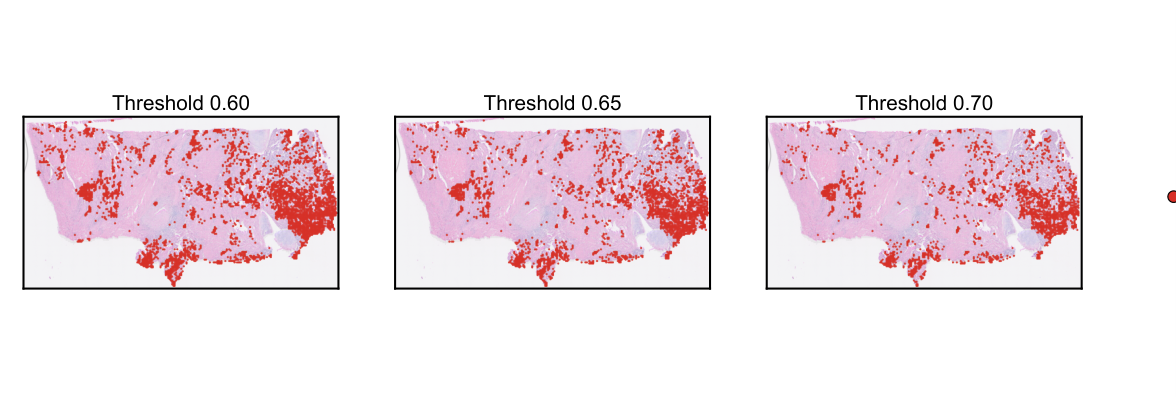

In [7]:
cancer = pd.read_csv(DATA / 'threshold_sensitivity' / 'inputs' / 'he_cancer_proxy_and_tumor_immune_tiles.csv')
thumb = np.load(require_path(DATA / 'threshold_sensitivity' / 'inputs' / 'visium_hd_he_thumbnail_stride32.npy'))
page = json.loads(require_path(DATA / 'threshold_sensitivity' / 'inputs' / 'visium_hd_he_page_info.json').read_text())
fig = plt.figure(figsize=(14.2, 4.8))
gs = fig.add_gridspec(1, 3, wspace=0.18)
for i, threshold in enumerate([0.60, 0.65, 0.70]):
    ax = fig.add_subplot(gs[0, i])
    spatial_threshold_map(ax, cancer, threshold, thumb, page)
handles = [Line2D([0], [0], marker='o', color='none', markerfacecolor='#d73027', markeredgecolor='black', markersize=10, label='Tumor-enriched tiles')]
fig.legend(handles=handles, frameon=False, loc='center left', bbox_to_anchor=(0.985, 0.50), handletextpad=0.25)
fig.subplots_adjust(left=0.02, right=0.92, bottom=0.08, top=0.90)
save_and_display(fig, 'sfig2_D_threshold_spatial_maps', zoom=1.15, tight=False)


## Panel e


saved: ./outputs/sfig2_panels/sfig2_E_domain_marker_heatmap.pdf
saved: ./outputs/sfig2_panels/sfig2_E_domain_marker_heatmap.png


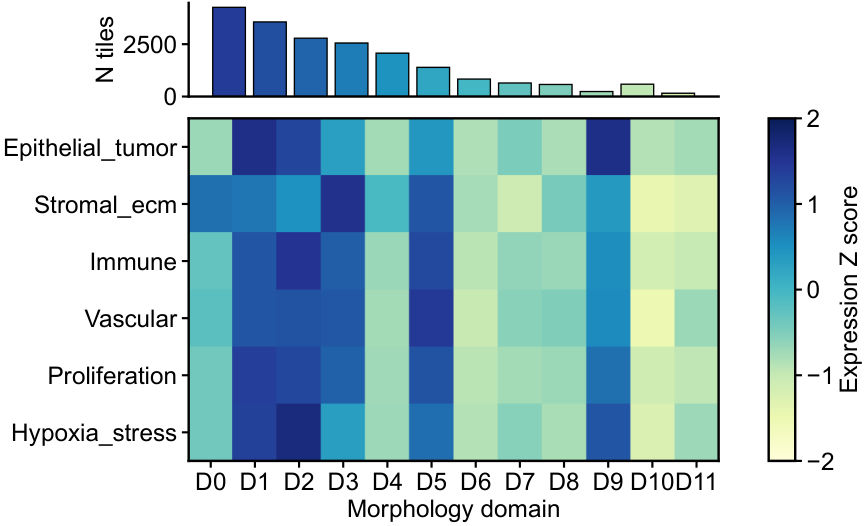

In [8]:
validation = pd.read_csv(DATA / 'domain_marker_validation' / 'tables' / 'visium_marker_validation_by_gigapath_domain_omicos3.csv')
tiles = pd.read_csv(DATA / 'domain_marker_validation' / 'inputs' / 'visium_hd_tile_features_minimal.csv')
marker_order = ['epithelial_tumor', 'stromal_ecm', 'immune', 'vascular', 'proliferation', 'hypoxia_stress']
marker_labels = ['Epithelial_tumor', 'Stromal_ecm', 'Immune', 'Vascular', 'Proliferation', 'Hypoxia_stress']
domains = sorted(validation['smoothed_domain'].unique(), key=natural_key)
val_pivot = validation.pivot(index='marker_group', columns='smoothed_domain', values='mean_expression').reindex(index=marker_order).reindex(columns=domains)
val_z = row_zscore(val_pivot)
val_z.index = marker_labels
val_z.columns = [domain_display_label(v) for v in domains]
counts = tiles['smoothed_domain'].value_counts().reindex(domains).fillna(0).astype(int)
fig = plt.figure(figsize=(8.0, 6.2))
gs = fig.add_gridspec(2, 2, height_ratios=[0.82, 3.0], width_ratios=[20, 1], hspace=0.10, wspace=0.18)
ax_bar = fig.add_subplot(gs[0, 0])
bar_colors = mpl.cm.YlGnBu(np.linspace(0.85, 0.20, len(domains)))
ax_bar.bar(np.arange(len(domains)), counts.to_numpy(), color=bar_colors, edgecolor='black', linewidth=1.0)
ax_bar.set_ylabel('N tiles')
ax_bar.set_xticks([])
style_axis(ax_bar)
ax = fig.add_subplot(gs[1, 0])
im = ax.imshow(val_z.to_numpy(float), aspect='auto', cmap='YlGnBu', vmin=-2, vmax=2)
ax.set_xticks(np.arange(len(val_z.columns)))
ax.set_xticklabels(val_z.columns)
ax.set_yticks(np.arange(len(val_z.index)))
ax.set_yticklabels(val_z.index)
ax.set_xlabel('Morphology domain')
style_heatmap_axis(ax)
cax = fig.add_subplot(gs[1, 1])
cb = fig.colorbar(im, cax=cax)
cb.set_label('Expression Z score')
style_colorbar(cb)
save_and_display(fig, 'sfig2_E_domain_marker_heatmap', zoom=1.35)


## Panel f


saved: ./outputs/sfig2_panels/sfig2_F_gene_mean_variance_correlation.pdf
saved: ./outputs/sfig2_panels/sfig2_F_gene_mean_variance_correlation.png


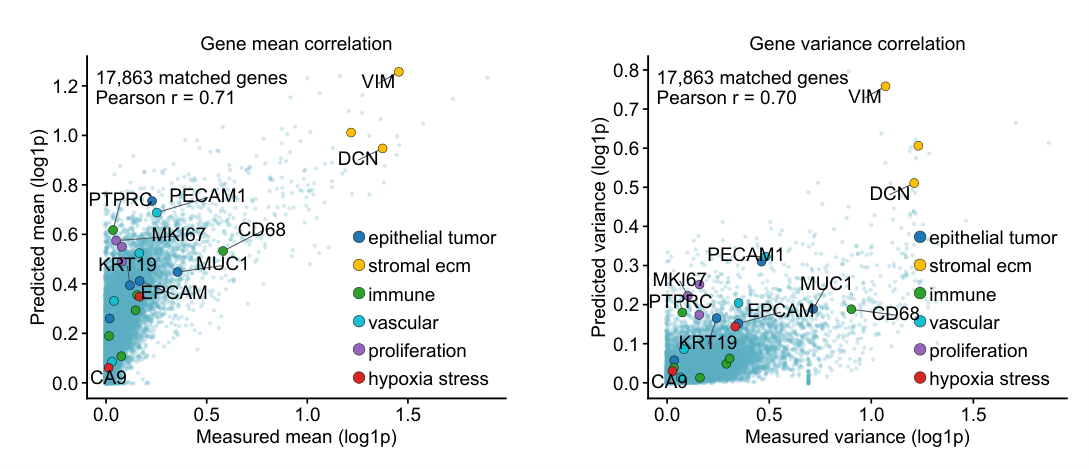

In [9]:
merged = pd.read_csv(DATA / 'non_he_validation' / 'tables' / 'full_data_predicted_vs_visium_gene_calibration_omicos7.csv')
MARKER_GROUPS = {
    'epithelial_tumor': ['EPCAM', 'KRT19', 'KRT8', 'KRT18', 'MUC1', 'SOX2'],
    'stromal_ecm': ['COL1A1', 'COL1A2', 'DCN', 'LUM', 'VIM'],
    'immune': ['PTPRC', 'CD3D', 'CD3E', 'CD68', 'LST1', 'MS4A1'],
    'vascular': ['PECAM1', 'VWF', 'KDR', 'EMCN'],
    'proliferation': ['MKI67', 'TOP2A', 'PCNA'],
    'hypoxia_stress': ['VEGFA', 'CA9', 'HIF1A'],
}
MARKER_COLORS = {'epithelial_tumor': '#1f77b4', 'stromal_ecm': '#ffbf00', 'immune': '#2ca02c', 'vascular': '#17becf', 'proliferation': '#9467bd', 'hypoxia_stress': '#d62728'}
LABEL_GENES = ['EPCAM', 'KRT19', 'MUC1', 'VIM', 'DCN', 'PTPRC', 'CD68', 'PECAM1', 'MKI67', 'CA9']
BACKGROUND_GENE_COLOR = '#5aaec2'

def plot_calibration_axis(ax, frame, x_col, y_col, title, subtitle):
    x = np.log1p(np.clip(frame[x_col].to_numpy(dtype=float), 0, None))
    y = np.log1p(np.clip(frame[y_col].to_numpy(dtype=float), 0, None))
    keep = np.isfinite(x) & np.isfinite(y)
    ax.scatter(x[keep], y[keep], s=18, c=BACKGROUND_GENE_COLOR, edgecolors='none', alpha=0.28, rasterized=True, zorder=1)
    ax.set_title(title, loc='center', fontweight='normal')
    ax.text(0.02, 0.96, subtitle, transform=ax.transAxes, ha='left', va='top', fontsize=18)
    x_label = x_col.replace('measured_', '').replace('_', ' ')
    y_label = y_col.replace('predicted_', '').replace('_', ' ')
    ax.set_xlabel(f'Measured {x_label} (log1p)')
    ax.set_ylabel(f'Predicted {y_label} (log1p)')
    style_axis(ax)

def overlay_markers(ax, frame, x_col, y_col):
    for group, genes in MARKER_GROUPS.items():
        sub = frame[frame['symbol'].isin(genes)]
        if sub.empty:
            continue
        ax.scatter(np.log1p(np.clip(sub[x_col], 0, None)), np.log1p(np.clip(sub[y_col], 0, None)), s=72, facecolor=MARKER_COLORS[group], edgecolor='black', linewidth=0.45, zorder=5, label=group.replace('_', ' '))
    label_frame = frame[frame['symbol'].isin(LABEL_GENES)]
    texts = []
    label_x = []
    label_y = []
    for _, row in label_frame.iterrows():
        x = np.log1p(max(float(row[x_col]), 0))
        y = np.log1p(max(float(row[y_col]), 0))
        texts.append(ax.text(x, y, row['symbol'], fontsize=18, ha='center', va='center', zorder=6))
        label_x.append(x)
        label_y.append(y)
    if texts and adjust_text is not None:
        adjust_text(texts, x=label_x, y=label_y, target_x=label_x, target_y=label_y, ax=ax, expand=(1.15, 1.35), force_text=(0.35, 0.65), force_static=(0.15, 0.35), force_pull=(0.02, 0.02), max_move=(18, 18), min_arrow_len=0, iter_lim=600, arrowprops={'arrowstyle': '-', 'color': '#4b5563', 'lw': 1.0, 'shrinkA': 0, 'shrinkB': 3})

def marker_legend_handles():
    return [Line2D([0], [0], marker='o', color='none', markerfacecolor=color, markeredgecolor='black', markeredgewidth=0.45, markersize=11, label=group.replace('_', ' ')) for group, color in MARKER_COLORS.items()]

mean_x = np.log1p(np.clip(merged['measured_mean'].to_numpy(dtype=float), 0, None))
mean_y = np.log1p(np.clip(merged['predicted_mean'].to_numpy(dtype=float), 0, None))
var_x = np.log1p(np.clip(merged['measured_variance'].to_numpy(dtype=float), 0, None))
var_y = np.log1p(np.clip(merged['predicted_variance'].to_numpy(dtype=float), 0, None))
mean_subtitle = f'{len(merged):,} matched genes' + chr(10) + f'Pearson r = {pearsonr(mean_x, mean_y)[0]:.2f}'
var_subtitle = f'{len(merged):,} matched genes' + chr(10) + f'Pearson r = {pearsonr(var_x, var_y)[0]:.2f}'
fig, axes = plt.subplots(1, 2, figsize=(14.4, 6.2), constrained_layout=False)
plot_calibration_axis(axes[0], merged, 'measured_mean', 'predicted_mean', 'Gene mean correlation', mean_subtitle)
overlay_markers(axes[0], merged, 'measured_mean', 'predicted_mean')
axes[0].legend(handles=marker_legend_handles(), loc='lower right', frameon=False, ncol=1, handlelength=0.8, handletextpad=0.08)
plot_calibration_axis(axes[1], merged, 'measured_variance', 'predicted_variance', 'Gene variance correlation', var_subtitle)
overlay_markers(axes[1], merged, 'measured_variance', 'predicted_variance')
axes[1].legend(handles=marker_legend_handles(), loc='lower right', frameon=False, ncol=1, handlelength=0.8, handletextpad=0.08)
fig.subplots_adjust(left=0.08, right=0.98, bottom=0.15, top=0.88, wspace=0.34)
save_and_display(fig, 'sfig2_F_gene_mean_variance_correlation', zoom=1.05, tight=False)


## Panel g


saved: ./outputs/sfig2_panels/sfig2_G_luad_risk_region_fractions.pdf
saved: ./outputs/sfig2_panels/sfig2_G_luad_risk_region_fractions.png


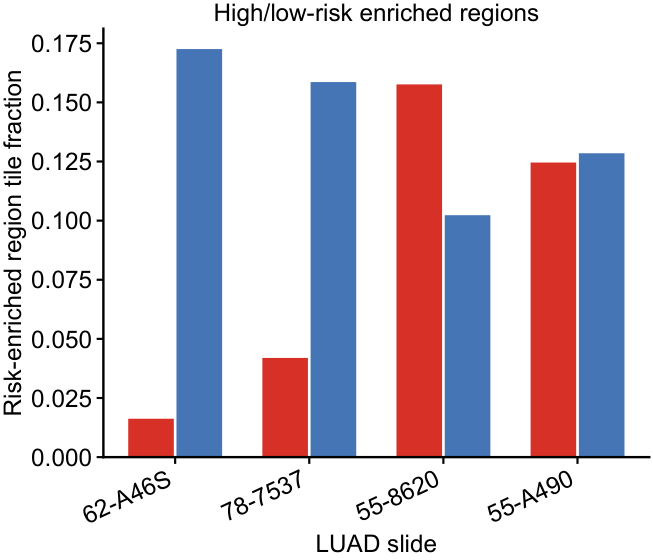

In [10]:
comp = pd.read_csv(DATA / 'luad_region_quantification' / 'tables' / 'supp_fig4_luad_region_composition.csv')
feature_order = ['Mixed C5: high-risk enriched', 'Shared C6: low-risk enriched']
feature_colors = {'Mixed C5: high-risk enriched': '#d73027', 'Shared C6: low-risk enriched': '#4575b4'}
feature_labels = {'Mixed C5: high-risk enriched': 'High-risk enriched regions', 'Shared C6: low-risk enriched': 'Low-risk enriched regions'}
patients = comp[['patient_id', 'risk_group']].drop_duplicates().sort_values(['risk_group', 'patient_id'], ascending=[False, True])
x = np.arange(len(patients))
fig, ax = plt.subplots(figsize=(7.2, 5.8))
key = comp.loc[comp['region_feature'].isin(feature_order)].copy()
for feature in feature_order:
    sub = key.loc[key['region_feature'].eq(feature)]
    vals = [float(sub.loc[sub['patient_id'].eq(patient), 'fraction'].iloc[0]) for patient in patients['patient_id']]
    ax.bar(x + (-0.18 if feature.startswith('Mixed') else 0.18), vals, width=0.34, color=feature_colors[feature], label=feature_labels[feature])
ax.set_xticks(x)
ax.set_xticklabels([p.replace('TCGA-', '') for p in patients['patient_id']], rotation=25, ha='right')
ax.set_xlabel('LUAD slide')
ax.set_ylabel('Risk-enriched region tile fraction')
ax.set_title('High/low-risk enriched regions')
style_axis(ax)
save_and_display(fig, 'sfig2_G_luad_risk_region_fractions', zoom=1.35)


## Panel h


saved: ./outputs/sfig2_panels/sfig2_H_luad_proxy_differences.pdf
saved: ./outputs/sfig2_panels/sfig2_H_luad_proxy_differences.png


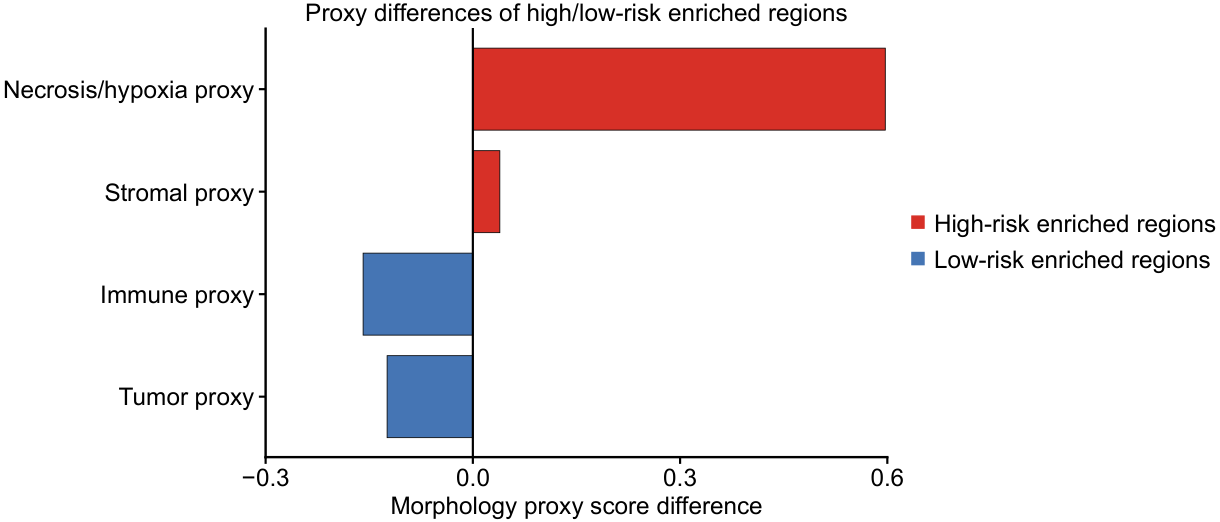

In [11]:
proxy_tests = pd.read_csv(DATA / 'luad_region_quantification' / 'tables' / 'supp_fig4_luad_region_proxy_tests.csv')
proxy_order = ['tumor_proxy_score', 'immune_proxy_score', 'stromal_proxy_score', 'necrosis_proxy_score']
proxy_labels = {'tumor_proxy_score': 'Tumor proxy', 'immune_proxy_score': 'Immune proxy', 'stromal_proxy_score': 'Stromal proxy', 'necrosis_proxy_score': 'Necrosis/hypoxia proxy'}
table = proxy_tests.set_index('proxy').reindex(proxy_order)
values = table['delta_mean'].astype(float).to_numpy()
y = np.arange(len(proxy_order))
colors = ['#d73027' if value >= 0 else '#4575b4' for value in values]
fig, ax = plt.subplots(figsize=(8.2, 5.8))
ax.barh(y, values, color=colors, edgecolor='black', linewidth=0.6)
ax.axvline(0, color='black', linewidth=1.6)
ax.set_yticks(y)
ax.set_yticklabels([proxy_labels[p] for p in proxy_order])
ax.set_xlabel('Morphology proxy score difference')
ax.set_title('Proxy differences of high/low-risk enriched regions')
ax.set_xlim(-0.3, 0.6)
ax.set_xticks(np.arange(-0.3, 0.61, 0.3))
style_axis(ax)
handles = [Line2D([0], [0], marker='s', linestyle='none', color='#d73027', label='High-risk enriched regions', markersize=9), Line2D([0], [0], marker='s', linestyle='none', color='#4575b4', label='Low-risk enriched regions', markersize=9)]
ax.legend(handles=handles, frameon=False, loc='center left', bbox_to_anchor=(1.02, 0.5), handletextpad=0.4)
save_and_display(fig, 'sfig2_H_luad_proxy_differences', zoom=1.35)


In [12]:
manifest_frame = refresh_manifest()
print(f'Manifest written to: {MANIFEST}')
display(manifest_frame.groupby(manifest_frame['path'].str.split('/').str[0]).size().rename('n_files').reset_index())


Manifest written to: ./MANIFEST_sfig2.json


      path  n_files
0     data       38
1  outputs       26
2  scripts        5

In [13]:
!pip list


Package                    Version
-------------------------- --------------
absl-py                    2.3.1
aiofiles                   25.1.0
anndata                    0.10.5.post1
annotated-types            0.7.0
anyio                      4.13.0
archspec                   0.2.3
argon2-cffi                23.1.0
argon2-cffi-bindings       21.2.0
array-api-compat           1.14.0
arrow                      1.3.0
asciitree                  0.3.3
asttokens                  2.4.1
async-lru                  2.0.4
attrs                      24.2.0
babel                      2.16.0
backrefs                   5.9
beautifulsoup4             4.12.3
bleach                     6.2.0
boltons                    24.0.0
Brotli                     1.1.0
build                      1.5.0
cached-property            1.5.2
cellrank                   2.0.7
certifi                    2026.5.20
cffi                       1.16.0
charset-normalizer         3.3.2
chex                       0.1.90
click       